# Student 2 Individual Notebook

Kaitlin Luu

Student 2: TWO ensemble methods: one Bagging-type model (e.g., Random Forest) AND one Boosting-type model (e.g., Gradient Boosting).

## Data Preparation

This section loads the training data and separates the target variable `dlq_2yrs` from the predictors. The data is also split 80/20 with stratification. The 20% holdout is only used for the final evaluation. The random state of 1234 supports reproducibility. 

In [44]:
# read in data

import pandas as pd
df = pd.read_csv("../../Data/training.csv")
df.head()

,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
0,0.793106,35.0,1.0,0.098301,3000.0,3.0,0.0,0.0,1.0,4.0,1
1,1.000000,43.0,4.0,0.857017,2272.0,5.0,0.0,2.0,0.0,2.0,1
2,0.772902,78.0,0.0,2.414651,2811.0,21.0,0.0,1.0,0.0,0.0,0
3,2.099010,43.0,0.0,0.033319,2400.0,1.0,0.0,0.0,0.0,0.0,0
4,0.266185,49.0,0.0,0.179646,40000.0,16.0,0.0,3.0,0.0,3.0,0


In [45]:
# prepare data

X = df.drop(columns=['dlq_2yrs'])
y = df['dlq_2yrs']
print(X.head())
print(y)

   rev_util   age  late_30_59  debt_ratio  monthly_inc  open_credit  late_90  \
0  0.793106  35.0         1.0    0.098301       3000.0          3.0      0.0   
1  1.000000  43.0         4.0    0.857017       2272.0          5.0      0.0   
2  0.772902  78.0         0.0    2.414651       2811.0         21.0      0.0   
3  2.099010  43.0         0.0    0.033319       2400.0          1.0      0.0   
4  0.266185  49.0         0.0    0.179646      40000.0         16.0      0.0   

   real_estate  late_60_89  dependents  
0          0.0         1.0         4.0  
1          2.0         0.0         2.0  
2          1.0         0.0         0.0  
3          0.0         0.0         0.0  
4          3.0         0.0         3.0  
0        1
1        1
2        0
3        0
4        0
        ..
13366    0
13367    1
13368    0
13369    1
13370    0
Name: dlq_2yrs, Length: 13371, dtype: int64


In [46]:
# 80/20 split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=1234
)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (10696, 10)  Test: (2675, 10)


## Cross-Validation

Stratified 5-fold cross-validation is used on the training data to test each model across five different splits, while keeping the proportion of delinquent and non-delinquent individuals consistent in each split.

Missing values are filled using the median within each fold to prevent data leakage.

GridSearchCV tested different hyperparameter combinations and selected the one with the highest average ROC-AUC across the five folds, which measures how well the model distinguishes between delinquent and non-delinquent individuals.

In [47]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

## Model 1: Random Forest (Bagging)

Random Forest trains multiple decision trees on bootstrap samples of the data (bagging) using random samples of the data and features, and then combines their predictions. This helps reduce overfitting compared to just one tree. 

The hyperparameters tested include:
* number of trees (`n_estimators`)
* the maximum tree depth (`max_depth`)
* the minimum number of observations per leaf (`min_samples_leaf`)
* number of features considered at each split (`max_features`).

These settings control how complex the model is and how well it generalizes to new data.

In [48]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(random_state=1234, n_jobs=-1))
])

rf_grid_params = {
    'model__n_estimators': [100, 300],
    'model__max_depth': [5, 10, None],
    'model__min_samples_leaf': [1, 5],
    'model__max_features': ['sqrt', 0.5]
}

rf_grid = GridSearchCV(rf_pipe, rf_grid_params, cv=cv, scoring='roc_auc',
                       n_jobs=1, refit=True, verbose=1)

# fit on training data
rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best mean CV ROC-AUC:", round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest parameters: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 100}
Best mean CV ROC-AUC: 0.8513


## Model 2: Gradient Boosting (Boosting)

Gradient Boosting trains decision trees by building them one at at ime, with each new tree trying to correct the errors of the previous ones. This allows the model to gradually improve its predictions, but it can overfit if it becomes too complex.

The hyperparameters tested include:
* number of trees (`n_estimators`)
* learning rate (`learning_rate`)
* the maximum tree depth (`max_depth`)
* the fraction of data used for each tree (`subsample`)

These settings control how quickly the model learns, how complex it becomes, and how much randomness is introduced during training.

In [49]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingClassifier(random_state=1234))
])

gb_grid_params = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3, 4],
    'model__subsample': [0.8, 1.0]
}

gb_grid = GridSearchCV(gb_pipe, gb_grid_params, cv=cv, scoring='roc_auc',
                       n_jobs=-1, refit=True, verbose=1)
gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:", gb_grid.best_params_)
print("Best mean CV ROC-AUC:", round(gb_grid.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Gradient Boosting parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best mean CV ROC-AUC: 0.8535


## Presentation of Results

**Cross-Validation Results and Model Comparison:**

The two ensemble models are compared using stratified 5-fold cross-validation on the training data, with the tables showing all tested hyperparameter combinations ranked by their average ROC-AUC score and how much the scores varied across the five folds.

The best version of each model is then evaluated using multiple metrics, including accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC, to provide a more complete picture of its performance. 

Because the models were selected using these cross-validation results, the scores may be slightly optimistic, so the holdout test set is used to provide a more reliable evaluation of how well the models perform on unseen data.

In [50]:
# all explored combinations for Random Forest with their CV results
rf_table = pd.DataFrame(rf_grid.cv_results_['params'])
rf_table.columns = rf_table.columns.str.replace('model__', '')

rf_table['Mean CV ROC-AUC'] = rf_grid.cv_results_['mean_test_score']
rf_table['CV Standard Deviation'] = rf_grid.cv_results_['std_test_score']
rf_table['Rank'] = rf_grid.cv_results_['rank_test_score']

rf_table = rf_table.sort_values('Rank').reset_index(drop=True)

print("Random Forest combinations:", len(rf_table))
rf_table

Random Forest combinations: 24


,max_depth,max_features,min_samples_leaf,n_estimators,Mean CV ROC-AUC,CV Standard Deviation,Rank
0,10.0,sqrt,5,100,0.851267,0.008291,1
1,10.0,sqrt,5,300,0.851126,0.008008,2
2,10.0,sqrt,1,300,0.850055,0.008790,3
3,10.0,sqrt,1,100,0.849532,0.008691,4
4,10.0,0.5,5,300,0.848654,0.008187,5
5,10.0,0.5,5,100,0.848612,0.008113,6
6,10.0,0.5,1,300,0.847765,0.008652,7
7,NaN,sqrt,5,300,0.847485,0.008386,8
8,10.0,0.5,1,100,0.847219,0.008400,9
9,5.0,sqrt,1,300,0.846990,0.008625,10


In [51]:
# all explored combinations for Gradient Boosting with their CV results
gb_table = pd.DataFrame(gb_grid.cv_results_['params'])
gb_table.columns = gb_table.columns.str.replace('model__', '')

gb_table['Mean CV ROC-AUC'] = gb_grid.cv_results_['mean_test_score']
gb_table['CV Standard Deviation'] = gb_grid.cv_results_['std_test_score']
gb_table['Rank'] = gb_grid.cv_results_['rank_test_score']

gb_table = gb_table.sort_values('Rank').reset_index(drop=True)

print("Gradient Boosting combinations:", len(gb_table))
gb_table

Gradient Boosting combinations: 24


,learning_rate,max_depth,n_estimators,subsample,Mean CV ROC-AUC,CV Standard Deviation,Rank
0,0.10,2,200,0.8,0.853486,0.008540,1
1,0.10,2,200,1.0,0.853469,0.009096,2
2,0.05,3,200,1.0,0.853167,0.008753,3
3,0.05,3,200,0.8,0.853127,0.008344,4
4,0.10,3,100,0.8,0.853103,0.009147,5
5,0.05,4,200,1.0,0.852981,0.008778,6
6,0.10,4,100,1.0,0.852813,0.009238,7
7,0.10,3,100,1.0,0.852761,0.009280,8
8,0.05,4,100,0.8,0.852514,0.008326,9
9,0.05,4,200,0.8,0.852507,0.008735,10


In [52]:
# cross-validation performance comparison

from sklearn.model_selection import cross_validate

models = {
    'Random Forest (Bagging)': rf_grid.best_estimator_,
    'Gradient Boosting (Boosting)': gb_grid.best_estimator_
}

scoring = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall',
           'F1': 'f1', 'ROC-AUC': 'roc_auc', 'PR-AUC': 'average_precision'}

rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'Model': name}
    for metric in scoring:
        row[f'{metric} (mean)'] = s[f'test_{metric}'].mean()
        row[f'{metric} (std)'] = s[f'test_{metric}'].std()
    rows.append(row)

cv_summary = pd.DataFrame(rows).set_index('Model').round(4)
cv_summary

,Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),F1 (mean),F1 (std),ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std)
Model,,,,,,,,,,,,
Random Forest (Bagging),0.7785,0.0081,0.793,0.0108,0.7539,0.0073,0.7730,0.0077,0.8513,0.0083,0.8513,0.0113
Gradient Boosting (Boosting),0.7757,0.0094,0.789,0.0146,0.7532,0.0064,0.7706,0.0079,0.8535,0.0085,0.8543,0.0106


**Hyperparameter Search Summary:**

The table summarizes the results of testing 24 hyperparameter combinations for each model using 5-fold cross-validation. For Random Forest, the best model used trees with a depth of 10, considered `sqrt` features at each split, and required at least 5 observations per leaf. Fully grown trees performed worse, likely because they overfit, while shallower trees may not have captured enough patterns. For Gradient Boosting, the best model used 200 trees, a learning rate of 0.1, a depth of 2, and 80% of the data per tree. Its performance stayed relatively similar across many settings, suggesting it was less sensitive to hyperparameter changes.

Although the best combinations were selected based on ROC-AUC, several performed very similarly, and the small differences may simply be due to variation between folds. Some of the best settings were also at the limits of the tested range, so testing additional values might improve results further.

In [53]:
# summary of the hyperparameter searches
search_summary = pd.DataFrame({
    'Model': ['Random Forest (Bagging)', 'Gradient Boosting (Boosting)'],
    'Combinations Tested': [len(rf_grid.cv_results_['params']),
                            len(gb_grid.cv_results_['params'])],
    'Best Mean CV ROC-AUC': [rf_grid.best_score_, gb_grid.best_score_],
    'CV Standard Deviation': [rf_grid.cv_results_['std_test_score'][rf_grid.best_index_],
                              gb_grid.cv_results_['std_test_score'][gb_grid.best_index_]],
    'Best Hyperparameters': [rf_grid.best_params_, gb_grid.best_params_]
})

search_summary

,Model,Combinations Tested,Best Mean CV ROC-AUC,CV Standard Deviation,Best Hyperparameters
0,Random Forest (Bagging),24,0.851267,0.008291,"{'model__max_depth': 10, 'model__max_features'..."
1,Gradient Boosting (Boosting),24,0.853486,0.008540,"{'model__learning_rate': 0.1, 'model__max_dept..."


**Evaluation across models:**

Both models are tested on a separate holdout test set of 2,675 observations that was not used during training or hyperparameter tuning, allowing us to see how well they perform on new data.

Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC are reported for both models. The test ROC-AUC scores (0.861 and 0.864) were slightly higher than the cross-validation scores (0.851 and 0.854), which may be because the final models were trained on more data and because performance can vary slightly depending on the data being evaluated.

In [54]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score)

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'PR-AUC': average_precision_score(y_test, prob)
    })

test_results = pd.DataFrame(rows).set_index('Model').round(4)
test_results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest (Bagging),0.7817,0.7900,0.7676,0.7786,0.8611,0.8608
Gradient Boosting (Boosting),0.7806,0.7909,0.7631,0.7767,0.8635,0.8628


**Confusion matrix analysis:**

The confusion matrices show how accurately each model classified individuals as either experiencing serious delinquency or not, using the default 0.5 threshold. They show correct predictions (true positives and true negatives) as well as mistakes (false positives and false negatives).

Both models performed very similarly, with the Random Forest correctly identifying 1,027 delinquency cases and Gradient Boosting identifying 1,021. They also made nearly the same number of incorrect predictions, resulting in similar precision (about 0.79) and recall (about 0.76–0.77). Both models missed roughly one in four actual delinquency cases, suggesting that lowering the classification threshold could help identify more cases, though it may also increase false positives.

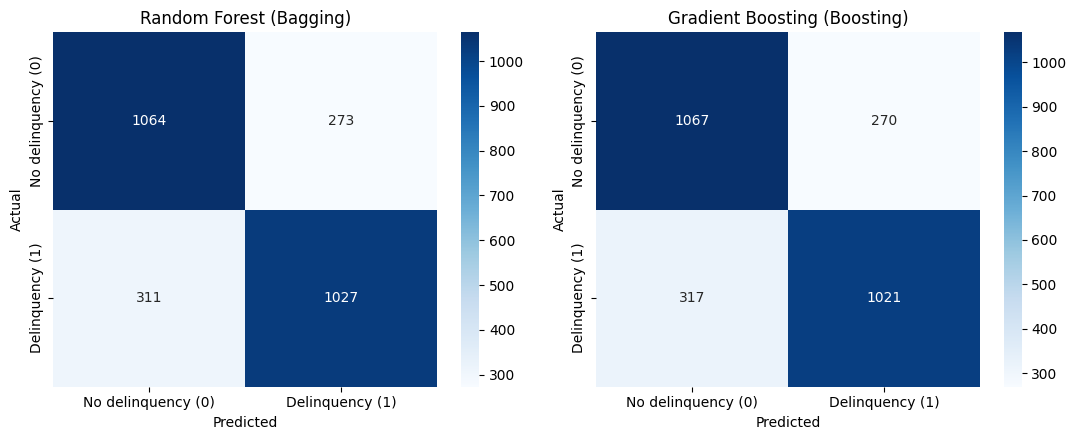

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No delinquency (0)', 'Delinquency (1)'],
                yticklabels=['No delinquency (0)', 'Delinquency (1)'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

**ROC Curve Comparison:**

ROC curves show how well each model can identify delinquent individuals while limiting incorrect predictions, as the classification threshold changes. A curve closer to the upper-left corner indicates better performance, while an AUC of 0.5 is equivalent to random guessing.

The Random Forest and Gradient Boosting curves almost overlap, with AUC scores of 0.861 and 0.864, respectively. Both models are reasonably good at distinguishing between delinquent and non-delinquent individuals, and neither appears to perform noticeably better than the other across different thresholds.

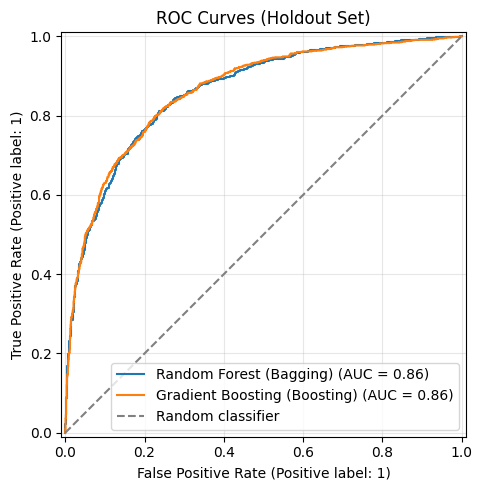

In [56]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random classifier')
ax.set_title('ROC Curves (Holdout Set)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Precision-Recall Curve Comparison:**

Precision-Recall curves show the tradeoff between how many delinquency cases the model correctly identifies (recall) and how accurate those predictions are (precision). Curves closer to the upper-right corner indicate better performance.

Both models have almost identical curves, with average precision scores of 0.861 and 0.863. At lower recall, precision is above 0.9, meaning most flagged individuals are actual delinquency cases. However, as the models identify more delinquency cases, precision decreases. This means that more false positive cases occur. This highlights the tradeoff between catching more at-risk individuals and making more incorrect predictions.

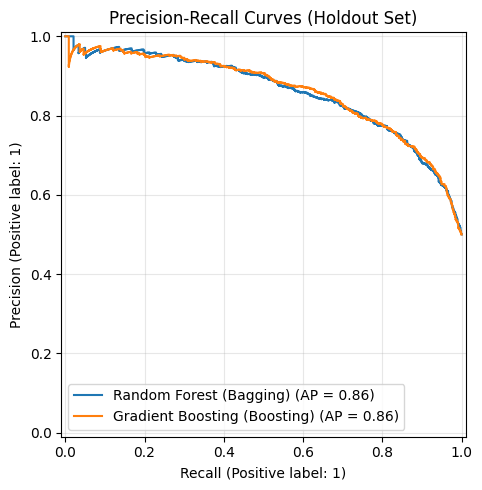

In [57]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
for name, m in models.items():
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.set_title('Precision-Recall Curves (Holdout Set)')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Tasks Completed and Findings

**Tasks completed:**
- Loaded the training data and created a stratified 80/20 train/holdout split (random state 1234).
- Built pipelines (median imputation + model) so preprocessing is fit inside each cross-validation fold, which prevents data leakage.
- Tuned a Random Forest (bagging) and a Gradient Boosting (boosting) classifier with `GridSearchCV` using stratified 5-fold cross-validation and ROC-AUC as the selection metric.
- Reported cross-validated results for every hyperparameter combination, evaluated the selected models with multiple metrics, and compared them on the holdout set using tables, confusion matrices, and ROC / precision-recall curves.

**Model Comparison and Findings:**

Both the Random Forest and Gradient Boosting models performed very similarly. During cross-validation, Gradient Boosting had a slightly higher mean ROC-AUC (0.8535 vs. 0.8513), but the difference was very small compared to the variation across folds. The best Random Forest settings were `max_depth = 10`, `max_features = 'sqrt'`, `min_samples_leaf = 5`, and `n_estimators = 100`. Gradient Boosting performed best with `learning_rate = 0.1`, `max_depth = 2`, `n_estimators = 200`, and `subsample = 0.8`.

The holdout results were also almost identical. Gradient Boosting had slightly higher ROC-AUC (0.8635 vs. 0.8611) and PR-AUC (0.8628 vs. 0.8608), while Random Forest had slightly higher accuracy (0.7817 vs. 0.7806) and recall (0.7676 vs. 0.7631). Precision was almost the same for both. The confusion matrices and curves were also very similar, so these small differences are not enough to say one model is better.

However, the models differed in their response to tuning. Random Forest was more sensitive to changes in its settings, while Gradient Boosting was more consistent and performed best with shallower trees. However, the tuning ranges were limited, and both models used the default 0.5 classification threshold, which resulted in missing about one-quarter of delinquency cases.

Overall, both models performed well, so either would be a reasonable choice. The main area of improvement would be wider hyperparameter searches or a lower decision threshold rather than in the choice of method.